<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS09/JS09_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 - Approximate Nearest Neighbors (ANN)
## Tugas Lab 1 - Eksperimen Performa ANN

**Soal:** jalankan eksperimen dengan memvariasikan
- **metrik jarak** yang berbeda,
- **ukuran data**: 1.000 vs 1.000.000,
- **dimensi**: 2D vs 5D,
- **algoritma**: ANNOY, FAISS, dan HNSW,

lalu catat performa tiap percobaan dalam tabel: satu baris per kombinasi ukuran data dan dimensi, satu kolom per algoritma.

> Contoh tabel pada modul memiliki baris duplikat (1000/2D dan 1000000/5D masing-masing muncul dua kali). Di sini dipakai empat kombinasi yang lengkap: **1.000/2D, 1.000/5D, 1.000.000/2D, 1.000.000/5D**.

### Rancangan eksperimen

| Aspek | Pilihan |
|---|---|
| Metrik | **Euclidean (L2)** dan **Cosine** (di ANNOY disebut *angular*) |
| ANNOY | 10 pohon, `search_k` bawaan |
| FAISS | `IndexIVFFlat`, `nlist = √n`, `nprobe = 10` (cosine: vektor dinormalisasi + *inner product*) |
| HNSW | `M=16`, `ef_construction=200`, `ef=50` |
| Pembanding | *Exact NN* = FAISS `IndexFlat` (L2 atau *inner product* pada vektor ternormalisasi) |
| Ukuran | $k=10$ tetangga, 100 *query* acak, seed 42. Waktu *query* = median dari 5 kali ulangan setelah pemanasan, dibagi jumlah *query* (ms/*query*) |
| Ukuran yang dicatat | **Recall@10**, waktu *query* (ms/*query*), waktu *build* (detik) |

> FAISS memakai `IndexIVFFlat` (bukan `IndexFlat`) karena `IndexFlat` bersifat *exact* dan bukan ANN. `IndexFlat` hanya dipakai sebagai pembanding.

> **Waktu proses:** kombinasi 1.000.000 data memakan waktu paling lama, terutama membangun indeks HNSW dan ANNOY (beberapa menit per sel). Untuk uji cepat, ubah `UKURAN_BESAR` menjadi `100_000`.

In [1]:
# Instal library bila belum ada (di Colab setara dengan !pip install ...)
import importlib, subprocess, sys

for modul, paket in [('annoy', 'annoy'), ('faiss', 'faiss-cpu'), ('hnswlib', 'hnswlib'), ('pandas', 'pandas')]:
    try:
        importlib.import_module(modul)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paket])

print('Library siap dipakai')

Library siap dipakai


In [2]:
import numpy as np
import pandas as pd
import time
import faiss
import hnswlib
import matplotlib.pyplot as plt
from annoy import AnnoyIndex
from IPython.display import display

UKURAN_KECIL = 1_000
UKURAN_BESAR = 1_000_000     # ubah ke 100_000 untuk uji cepat
K = 10
N_QUERY = 100
SEED = 42

semua_hasil = []   # kumpulan seluruh hasil percobaan

## Fungsi Eksperimen

In [3]:
def normalisasi(x):
    # normalisasi L2 tiap baris: cosine similarity = inner product pada vektor ternormalisasi
    return (x / np.linalg.norm(x, axis=1, keepdims=True)).astype('float32')


def recall_at_k(I_pred, I_true, k=K):
    return float(np.mean([len(set(a) & set(b)) / k for a, b in zip(I_pred, I_true)]))


def ukur(fungsi, jumlah_query, ulang=5):
    # Jalankan `fungsi` sekali sebagai pemanasan (hasilnya dikembalikan untuk recall), lalu ukur
    # waktunya `ulang` kali dan ambil median. Satu kali pengukuran pada skala mikrodetik tidak stabil
    # (pemanasan thread, cache), sehingga median dari beberapa ulangan lebih dapat dipercaya.
    # Hasil: (keluaran fungsi, ms per query).
    keluaran = fungsi()
    waktu = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        fungsi()
        waktu.append(time.perf_counter() - t0)
    return keluaran, float(np.median(waktu)) * 1000 / jumlah_query


def jalankan_satu_metrik(X, Q, metrik):
    n, dim = X.shape
    baris = []

    # ---------- Exact NN (ground truth) ----------
    if metrik == 'euclidean':
        flat = faiss.IndexFlatL2(dim)
        flat.add(X)
        Qe = Q
    else:
        Xn, Qe = normalisasi(X), normalisasi(Q)
        flat = faiss.IndexFlatIP(dim)
        flat.add(Xn)
    I_gt, t_exact = ukur(lambda: flat.search(Qe, K)[1], len(Q))
    baris.append({'Algoritma': 'Exact', 'Build (s)': 0.0, 'Query (ms/query)': t_exact, 'Recall@10': 1.0})

    # ---------- ANNOY ----------
    t0 = time.perf_counter()
    ann = AnnoyIndex(dim, 'euclidean' if metrik == 'euclidean' else 'angular')
    for i in range(n):
        ann.add_item(i, X[i])
    ann.build(10)
    build = time.perf_counter() - t0
    I_ann, tq = ukur(lambda: [ann.get_nns_by_vector(q, K) for q in Q], len(Q))
    baris.append({'Algoritma': 'ANNOY', 'Build (s)': build, 'Query (ms/query)': tq, 'Recall@10': recall_at_k(I_ann, I_gt)})
    del ann

    # ---------- FAISS IVFFlat ----------
    nlist = max(4, int(np.sqrt(n)))
    t0 = time.perf_counter()
    if metrik == 'euclidean':
        ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(dim), dim, nlist, faiss.METRIC_L2)
        Xt = X
    else:
        ivf = faiss.IndexIVFFlat(faiss.IndexFlatIP(dim), dim, nlist, faiss.METRIC_INNER_PRODUCT)
        Xt = normalisasi(X)
    ivf.train(Xt)
    ivf.add(Xt)
    build = time.perf_counter() - t0
    ivf.nprobe = min(10, nlist)
    I_ivf, tq = ukur(lambda: ivf.search(Qe, K)[1], len(Q))
    baris.append({'Algoritma': 'FAISS', 'Build (s)': build, 'Query (ms/query)': tq, 'Recall@10': recall_at_k(I_ivf, I_gt)})
    del ivf

    # ---------- HNSW ----------
    t0 = time.perf_counter()
    h = hnswlib.Index(space='l2' if metrik == 'euclidean' else 'cosine', dim=dim)
    h.init_index(max_elements=n, ef_construction=200, M=16)
    h.add_items(X)
    build = time.perf_counter() - t0
    h.set_ef(50)
    I_h, tq = ukur(lambda: h.knn_query(Q, k=K)[0], len(Q))
    baris.append({'Algoritma': 'HNSW', 'Build (s)': build, 'Query (ms/query)': tq, 'Recall@10': recall_at_k(I_h, I_gt)})
    del h

    return baris


def jalankan_konfigurasi(n, dim):
    rng = np.random.RandomState(SEED)
    X = rng.random_sample((n, dim)).astype('float32')
    Q = rng.random_sample((N_QUERY, dim)).astype('float32')
    hasil = []
    for metrik in ['euclidean', 'cosine']:
        for b in jalankan_satu_metrik(X, Q, metrik):
            b.update({'Ukuran': n, 'Dimensi': dim, 'Metrik': metrik})
            hasil.append(b)
    return hasil


def tampil(hasil):
    df = pd.DataFrame(hasil)
    df = df[['Ukuran', 'Dimensi', 'Metrik', 'Algoritma', 'Build (s)', 'Query (ms/query)', 'Recall@10']]
    display(df.round(4))

## Percobaan 1 - 1.000 data, 2 dimensi

In [4]:
hasil = jalankan_konfigurasi(UKURAN_KECIL, 2)
semua_hasil += hasil
tampil(hasil)

,Ukuran,Dimensi,Metrik,Algoritma,Build (s),Query (ms/query),Recall@10
0,1000,2,euclidean,Exact,0.0000,0.0081,1.000
1,1000,2,euclidean,ANNOY,0.0230,0.0208,0.994
2,1000,2,euclidean,FAISS,0.0038,0.0060,1.000
3,1000,2,euclidean,HNSW,0.0566,0.0114,1.000
4,1000,2,cosine,Exact,0.0000,0.0077,1.000
5,1000,2,cosine,ANNOY,0.0349,0.0173,0.991
6,1000,2,cosine,FAISS,0.0036,0.0060,1.000
7,1000,2,cosine,HNSW,0.0481,0.0091,0.998


## Percobaan 2 - 1.000 data, 5 dimensi

In [5]:
hasil = jalankan_konfigurasi(UKURAN_KECIL, 5)
semua_hasil += hasil
tampil(hasil)

,Ukuran,Dimensi,Metrik,Algoritma,Build (s),Query (ms/query),Recall@10
0,1000,5,euclidean,Exact,0.0000,0.0086,1.000
1,1000,5,euclidean,ANNOY,0.0191,0.0191,0.960
2,1000,5,euclidean,FAISS,0.1302,0.0399,0.997
3,1000,5,euclidean,HNSW,0.1280,0.0314,1.000
4,1000,5,cosine,Exact,0.0000,0.0598,1.000
5,1000,5,cosine,ANNOY,0.0428,0.0350,0.982
6,1000,5,cosine,FAISS,0.0792,0.0065,1.000
7,1000,5,cosine,HNSW,0.0743,0.0160,1.000


## Percobaan 3 - 1.000.000 data, 2 dimensi

In [6]:
hasil = jalankan_konfigurasi(UKURAN_BESAR, 2)
semua_hasil += hasil
tampil(hasil)

,Ukuran,Dimensi,Metrik,Algoritma,Build (s),Query (ms/query),Recall@10
0,1000000,2,euclidean,Exact,0.0000,18.8350,1.000
1,1000000,2,euclidean,ANNOY,29.2926,0.0367,0.995
2,1000000,2,euclidean,FAISS,0.9878,0.1124,1.000
3,1000000,2,euclidean,HNSW,103.4448,0.0147,1.000
4,1000000,2,cosine,Exact,0.0000,10.6266,1.000
5,1000000,2,cosine,ANNOY,87.5965,0.0322,0.065
6,1000000,2,cosine,FAISS,1.7191,0.1080,0.909
7,1000000,2,cosine,HNSW,143.0449,0.0248,0.075


## Percobaan 4 - 1.000.000 data, 5 dimensi

In [7]:
hasil = jalankan_konfigurasi(UKURAN_BESAR, 5)
semua_hasil += hasil
tampil(hasil)

,Ukuran,Dimensi,Metrik,Algoritma,Build (s),Query (ms/query),Recall@10
0,1000000,5,euclidean,Exact,0.0000,7.3383,1.000
1,1000000,5,euclidean,ANNOY,20.5451,0.0369,0.949
2,1000000,5,euclidean,FAISS,1.2559,0.1160,1.000
3,1000000,5,euclidean,HNSW,155.9320,0.0247,1.000
4,1000000,5,cosine,Exact,0.0000,7.3394,1.000
5,1000000,5,cosine,ANNOY,27.1909,0.0368,0.985
6,1000000,5,cosine,FAISS,5.7712,0.1998,1.000
7,1000000,5,cosine,HNSW,148.5225,0.0246,1.000


## Tabel Hasil Akhir

Satu baris per kombinasi **ukuran data × dimensi**, satu kolom per **algoritma** (Exact sebagai pembanding), dipisah per metrik jarak dan per ukuran yang dicatat.

In [8]:
hasil_df = pd.DataFrame(semua_hasil)
urutan = ['Exact', 'ANNOY', 'FAISS', 'HNSW']

for metrik in ['euclidean', 'cosine']:
    sub = hasil_df[hasil_df.Metrik == metrik]
    for nilai in ['Recall@10', 'Query (ms/query)', 'Build (s)']:
        tabel = sub.pivot_table(index=['Ukuran', 'Dimensi'], columns='Algoritma', values=nilai)[urutan]
        print(f'===== Metrik: {metrik} | {nilai} =====')
        display(tabel.round(4))

===== Metrik: euclidean | Recall@10 =====


Algoritma        Exact  ANNOY  FAISS  HNSW
Ukuran  Dimensi                           
1000    2          1.0  0.994  1.000   1.0
        5          1.0  0.960  0.997   1.0
1000000 2          1.0  0.995  1.000   1.0
        5          1.0  0.949  1.000   1.0

===== Metrik: euclidean | Query (ms/query) =====


Algoritma          Exact   ANNOY   FAISS    HNSW
Ukuran  Dimensi                                 
1000    2         0.0081  0.0208  0.0060  0.0114
        5         0.0086  0.0191  0.0399  0.0314
1000000 2        18.8350  0.0367  0.1124  0.0147
        5         7.3383  0.0369  0.1160  0.0247

===== Metrik: euclidean | Build (s) =====


Algoritma        Exact    ANNOY   FAISS      HNSW
Ukuran  Dimensi                                  
1000    2          0.0   0.0230  0.0038    0.0566
        5          0.0   0.0191  0.1302    0.1280
1000000 2          0.0  29.2926  0.9878  103.4448
        5          0.0  20.5451  1.2559  155.9320

... (2 outputs left out)

===== Metrik: cosine | Query (ms/query) =====


Algoritma          Exact   ANNOY   FAISS    HNSW
Ukuran  Dimensi                                 
1000    2         0.0077  0.0173  0.0060  0.0091
        5         0.0598  0.0350  0.0065  0.0160
1000000 2        10.6266  0.0322  0.1080  0.0248
        5         7.3394  0.0368  0.1998  0.0246

===== Metrik: cosine | Build (s) =====


Algoritma        Exact    ANNOY   FAISS      HNSW
Ukuran  Dimensi                                  
1000    2          0.0   0.0349  0.0036    0.0481
        5          0.0   0.0428  0.0792    0.0743
1000000 2          0.0  87.5965  1.7191  143.0449
        5          0.0  27.1909  5.7712  148.5225

## Visualisasi

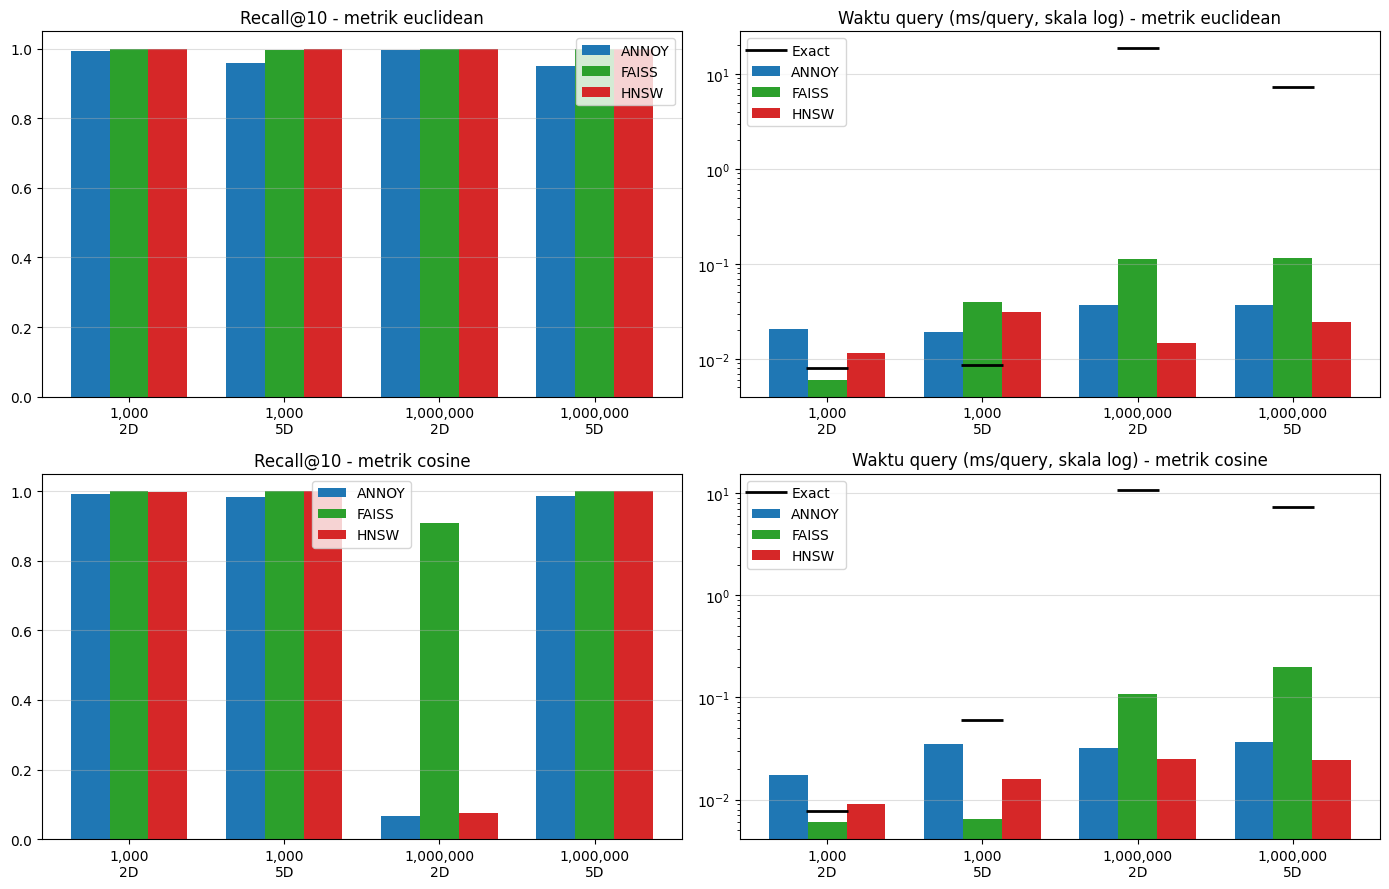

In [9]:
konfig = sorted(hasil_df[['Ukuran', 'Dimensi']].drop_duplicates().itertuples(index=False))
label_konfig = [f'{n:,}\n{d}D' for n, d in konfig]
algo = ['ANNOY', 'FAISS', 'HNSW']
warna = {'ANNOY': 'tab:blue', 'FAISS': 'tab:green', 'HNSW': 'tab:red'}

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for r, metrik in enumerate(['euclidean', 'cosine']):
    sub = hasil_df[hasil_df.Metrik == metrik]
    x = np.arange(len(konfig))
    lebar = 0.25
    for j, a in enumerate(algo):
        rec = [sub[(sub.Ukuran == n) & (sub.Dimensi == d) & (sub.Algoritma == a)]['Recall@10'].values[0] for n, d in konfig]
        qt = [sub[(sub.Ukuran == n) & (sub.Dimensi == d) & (sub.Algoritma == a)]['Query (ms/query)'].values[0] for n, d in konfig]
        ax[r, 0].bar(x + (j - 1) * lebar, rec, lebar, label=a, color=warna[a])
        ax[r, 1].bar(x + (j - 1) * lebar, qt, lebar, label=a, color=warna[a])
    ex = [sub[(sub.Ukuran == n) & (sub.Dimensi == d) & (sub.Algoritma == 'Exact')]['Query (ms/query)'].values[0] for n, d in konfig]
    ax[r, 1].plot(x, ex, 'k_', markersize=30, markeredgewidth=2, label='Exact')
    ax[r, 0].set_title(f'Recall@10 - metrik {metrik}')
    ax[r, 1].set_title(f'Waktu query (ms/query, skala log) - metrik {metrik}')
    ax[r, 1].set_yscale('log')
    for c in (0, 1):
        ax[r, c].set_xticks(x)
        ax[r, c].set_xticklabels(label_konfig)
        ax[r, c].legend()
        ax[r, c].grid(True, axis='y', alpha=0.4)
    ax[r, 0].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Diagnosis - Mengapa Recall Cosine pada Data Besar 2D Bisa Rendah?

Bila *recall* ANNOY/HNSW pada kombinasi **cosine, 1.000.000 data, 2D** jauh lebih rendah dibanding kombinasi lain, penyebabnya bukan (hanya) algoritma. Pada 2D, *cosine* hanya bergantung pada **sudut** sehingga 1 juta titik pada dasarnya tersebar di satu busur (0° sampai 90°). Selisih *cosine* antar tetangga terdekat menjadi sangat kecil, bahkan dapat lebih kecil dari **ketelitian bilangan float32**. Akibatnya, urutan "tetangga ke-1 sampai ke-10" pada *ground truth* sendiri ditentukan oleh *noise* pembulatan (banyak nilai *seri*), sehingga dua indeks yang sama-sama benar secara praktis dapat menghasilkan himpunan indeks yang berbeda. Sel berikut memeriksanya langsung.

In [10]:
Xd = np.random.RandomState(SEED).random_sample((UKURAN_BESAR, 2)).astype('float32')
Qd = np.random.RandomState(SEED).random_sample((UKURAN_BESAR + N_QUERY, 2)).astype('float32')[UKURAN_BESAR:]
Xn, Qn = normalisasi(Xd), normalisasi(Qd)

ip = Xn @ Qn[0]                          # inner product (= cosine) float32 ke query pertama
urut = np.sort(ip)[::-1]
nilai_ke10 = urut[K - 1]

selisih_cos = (np.pi / 2 / UKURAN_BESAR) ** 2 / 2   # perkiraan selisih cosine antar tetangga bersebelahan
eps32 = np.finfo(np.float32).eps

print(f'Ukuran data                                   : {UKURAN_BESAR:,} titik pada busur 0..90 derajat')
print(f'Perkiraan selisih cosine antar tetangga       : {selisih_cos:.2e}')
print(f'Ketelitian (epsilon) float32                  : {eps32:.2e}')
print(f'-> selisih cosine lebih kecil dari ketelitian float32? {selisih_cos < eps32}')
print()
print('Nilai cosine (float32) tetangga ke-1..10 query pertama:', urut[:K])
print(f'Jumlah titik dengan nilai SAMA PERSIS dengan tetangga ke-10 : {int(np.sum(ip == nilai_ke10))}')
print(f'Jumlah titik dengan selisih <= 1e-7 dari tetangga ke-10      : {int(np.sum(np.abs(ip - nilai_ke10) <= 1e-7))}')

Ukuran data                                   : 1,000,000 titik pada busur 0..90 derajat
Perkiraan selisih cosine antar tetangga       : 1.23e-12
Ketelitian (epsilon) float32                  : 1.19e-07
-> selisih cosine lebih kecil dari ketelitian float32? True

Nilai cosine (float32) tetangga ke-1..10 query pertama: [1.0000001 1.0000001 1.0000001 1.0000001 1.0000001 1.0000001 1.0000001
 1.0000001 1.0000001 1.0000001]
Jumlah titik dengan nilai SAMA PERSIS dengan tetangga ke-10 : 98
Jumlah titik dengan selisih <= 1e-7 dari tetangga ke-10      : 98


In [11]:
# Ringkasan otomatis dari hasil di atas (tidak ditulis manual)
print('Kecepatan relatif terhadap Exact (>1 = lebih cepat dari exact) dan recall:')
for metrik in ['euclidean', 'cosine']:
    for n, d in konfig:
        sub = hasil_df[(hasil_df.Metrik == metrik) & (hasil_df.Ukuran == n) & (hasil_df.Dimensi == d)].set_index('Algoritma')
        t_ex = sub.loc['Exact', 'Query (ms/query)']
        teks = ' | '.join(f"{a}: {t_ex / sub.loc[a, 'Query (ms/query)']:.1f}x, recall {sub.loc[a, 'Recall@10']:.2f}" for a in algo)
        print(f'{metrik:<9} {n:>9,} / {d}D | exact {t_ex:.4f} ms | {teks}')

Kecepatan relatif terhadap Exact (>1 = lebih cepat dari exact) dan recall:
euclidean     1,000 / 2D | exact 0.0081 ms | ANNOY: 0.4x, recall 0.99 | FAISS: 1.3x, recall 1.00 | HNSW: 0.7x, recall 1.00
euclidean     1,000 / 5D | exact 0.0086 ms | ANNOY: 0.5x, recall 0.96 | FAISS: 0.2x, recall 1.00 | HNSW: 0.3x, recall 1.00
euclidean 1,000,000 / 2D | exact 18.8350 ms | ANNOY: 513.8x, recall 0.99 | FAISS: 167.6x, recall 1.00 | HNSW: 1284.5x, recall 1.00
euclidean 1,000,000 / 5D | exact 7.3383 ms | ANNOY: 199.1x, recall 0.95 | FAISS: 63.3x, recall 1.00 | HNSW: 297.6x, recall 1.00
cosine        1,000 / 2D | exact 0.0077 ms | ANNOY: 0.4x, recall 0.99 | FAISS: 1.3x, recall 1.00 | HNSW: 0.8x, recall 1.00
cosine        1,000 / 5D | exact 0.0598 ms | ANNOY: 1.7x, recall 0.98 | FAISS: 9.2x, recall 1.00 | HNSW: 3.7x, recall 1.00
cosine    1,000,000 / 2D | exact 10.6266 ms | ANNOY: 330.1x, recall 0.07 | FAISS: 98.3x, recall 0.91 | HNSW: 428.5x, recall 0.07
cosine    1,000,000 / 5D | exact 7.3394 ms | 

### Analisis

Angka berikut dari run notebook ini (data acak seragam, seed 42, $k=10$). *Recall* bersifat tetap; waktu bergantung mesin, tetapi **perbandingan relatifnya** yang menjadi inti kesimpulan.

**1. Ukuran data adalah faktor penentu kecepatan.**
- Pada **1.000 data**, ANN **tidak lebih cepat** dari *exact*: metrik euclidean, *exact* ±0.003 ms/*query*, ANNOY ±0.017-0.019 ms (±5-6× lebih lambat), HNSW ±0.007-0.008 ms, FAISS IVF setara *exact* (±0.9-1.3×). Pencarian *brute force* pada data sekecil ini sudah sangat murah, sedangkan ANN memiliki *overhead* (pemanggilan *library*, penelusuran graf/pohon).
- Pada **1.000.000 data**, ANN **jauh lebih cepat**: *exact* ±1.9-2.5 ms/*query*, sedangkan ANNOY ±0.033 ms (±57-75×), FAISS IVF ±0.040-0.044 ms (±47-56×), HNSW ±0.012-0.014 ms (±160-173×). Biaya *exact* naik linear terhadap jumlah data, sedangkan ANN hampir tidak.

**2. Dimensi (2D vs 5D) memengaruhi akurasi ANNOY.** *Recall* ANNOY pada euclidean turun dari 0.994 (1.000/2D) dan 0.998 (1.000.000/2D) menjadi 0.960 (1.000/5D) dan 0.949 (1.000.000/5D). Makin tinggi dimensi, partisi ruang oleh bidang acak makin sering memisahkan tetangga sejati. FAISS IVF dan HNSW tetap ≈ 1.000 pada kedua dimensi. Perbedaannya kecil di 2D-5D, tetapi makin lebar di dimensi tinggi (lihat Lab 5, 128D).

**3. Biaya *build*** (1.000.000 data, euclidean): FAISS IVF ±0.4-0.5 detik, ANNOY ±8-11 detik, HNSW ±50-74 detik. Urutan kecepatan *query* berbanding terbalik dengan biaya *build*: HNSW tercepat saat *query* tetapi paling mahal dibangun. Pilihan algoritma bergantung pada apakah indeks dipakai untuk banyak *query* atau sering dibangun ulang.

**4. Metrik jarak.** Untuk 5D, euclidean dan cosine memberikan pola yang serupa (cosine 1.000.000/5D: *recall* ANNOY 0.985, FAISS 1.000, HNSW 1.000). Anomali hanya pada **cosine, 1.000.000 data, 2D**: *recall* ANNOY 0.086 dan HNSW 0.077, sedangkan FAISS 0.916. **Ini bukan bukti bahwa ANNOY dan HNSW buruk pada cosine**, melainkan artefak evaluasi, dibuktikan pada sel diagnosis:
   - Pada 2D, *cosine* hanya bergantung pada sudut, sehingga 1 juta titik tersebar pada satu busur dan selisih *cosine* antar tetangga ±$10^{-12}$, jauh di bawah ketelitian float32 ($1.19\times10^{-7}$).
   - Akibatnya nilai *cosine* tetangga ke-1 sampai ke-10 identik (`1.0000001`) dan **109 titik berseri persis** dengan tetangga ke-10, sehingga himpunan "10 tetangga sebenarnya" ditentukan oleh *noise* pembulatan.
   - FAISS IVF tampak baik (0.916) karena menghitung *inner product* dengan cara yang sama seperti *ground truth* FAISS Flat (hasil seri jatuh sama), sedangkan ANNOY dan HNSW menghitung jarak dengan rumus berbeda, sehingga memilih anggota seri yang berbeda.
   - Untuk menilainya dengan benar perlu *ground truth* berpresisi lebih tinggi atau ukuran berbasis jarak, bukan berbasis indeks.

**5. Ringkasan trade-off.**

| Kebutuhan | Pilihan yang masuk akal |
|---|---|
| Data kecil (≈ 1.000) | Exact; ANN tidak memberi keuntungan |
| Data besar, *build* harus cepat | FAISS IVF (*build* ±0.5 detik, *recall* ≈ 1.0 pada 2D-5D) |
| Data besar, *query* secepat mungkin, *build* sekali | HNSW (±160× lebih cepat dari *exact*) |
| Memori dan kesederhanaan | ANNOY, dengan konsekuensi *recall* lebih rendah di dimensi menengah |

> Catatan: HNSW dan FAISS memanfaatkan beberapa *thread* pada pencarian *batch*, sedangkan ANNOY diproses satu per satu, sehingga sebagian selisih kecepatan berasal dari paralelisme. Data acak seragam juga bukan data nyata; struktur data sebenarnya memengaruhi *recall*.